## Summarizing images from pinterest!

In [70]:
import sys
import os
from pathlib import Path
from playwright.async_api import async_playwright
from dotenv import load_dotenv
from IPython.display import Image, Markdown, display
from openai import OpenAI
import base64
import mimetypes

In [71]:
# load the env file
load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')

In [72]:
# define openai
openai=OpenAI()

### Step 1 : Get the images from pinterest board

In [73]:
# create a function to scrape the website and return the text content
async def fetch_images(url, output_dir, max_images=5, max_scrolls=20):
    if max_images < 1:
        raise ValueError("max_images must be at least 1")

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)
    image_urls = []

    async with async_playwright() as playwright:
        browser = await playwright.chromium.launch(headless=True)
        context = await browser.new_context()
        page = await context.new_page()

        try:
            await page.goto(url, wait_until="domcontentloaded", timeout=60_000)

            for _ in range(max_scrolls):
                image_urls = await page.locator("img").evaluate_all("""
                    imgs => [...new Set(imgs
                        .map(img => img.currentSrc || img.src)
                        .filter(src => src.startsWith('https://i.pinimg.com/')))]
                """)
                if len(image_urls) >= max_images:
                    break
                await page.evaluate("window.scrollBy(0, window.innerHeight)")
                await page.wait_for_timeout(1000)

            saved_files = []
            for index, image_url in enumerate(image_urls[:max_images], start=1):
                response = await context.request.get(image_url)
                if response.ok:
                    content_type = response.headers.get("content-type", "")
                    extension = content_type.split("/")[-1].split(";")[0]
                    if extension not in {"jpeg", "png", "webp", "gif"}:
                        extension = "jpg"

                    file_path = output_path / f"image_{index}.{extension}"
                    file_path.write_bytes(await response.body())
                    saved_files.append(str(file_path))

            return saved_files
        finally:
            await browser.close()

### Step 2 : Build the request

In [74]:
system_prompt = "You are an insightful assistant that summarizes the given images and uniquely and artistically interprets them.Please summarise each image in 2 lines and be creative in your interpretation of the images."
user_prompt_prefix = "Here are some images from my pinterest board. Please summarize them for me:\n\n"

In [75]:
def build_messages(images_path):
    image_content = []

    for image_path in images_path:
        mime_type, _ = mimetypes.guess_type(image_path)
        if mime_type is None:
            mime_type = "image/jpeg"
        encoded_image = base64.b64encode(Path(image_path).read_bytes()).decode("ascii")
        image_content.append({
            "type": "image_url",
            "image_url": {"url": f"data:{mime_type};base64,{encoded_image}"},
        })

    image_content.append({"type": "text", "text": user_prompt_prefix})

    return [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": image_content},
    ]

In [76]:
async def summarise_images(url):
    saved_files = await fetch_images(
        url,
        output_dir="../pinterest images",
        max_images=5,
        max_scrolls=20,
    )

    for image_path in saved_files:
        display(Image(filename=image_path))

        response = openai.chat.completions.create(
            model="gpt-4.1-mini",
            messages=build_messages([image_path]),
        )
        answer = response.choices[0].message.content
        display(Markdown(answer))

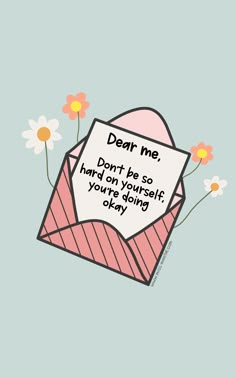

This image feels like a tender love letter from one's inner self, wrapped gently in pastel hues and blossoming flowers. It whispers a heartfelt reminder: to treat yourself with kindness and grace, embracing your journey with gentle encouragement.

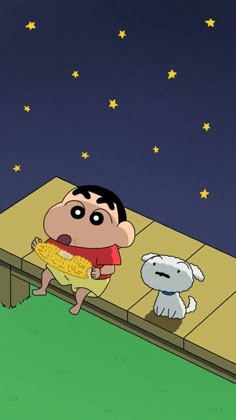

A whimsical night scene where a child and his loyal dog sit side by side, sharing a quiet moment under a sky sprinkled with bright yellow stars. The child’s wide-eyed wonder and the dog’s serene presence paint a picture of simple joys and peaceful companionship.

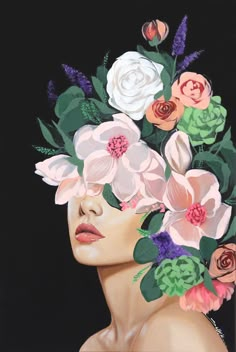

This image paints a surreal symphony where nature and human grace entwine, a portrait blossoming with delicate petals that veil the eyes and crown the soul. It’s as if the essence of springtime dreams has taken form, whispering secrets of beauty and mystery through floral hues and soft shadows.

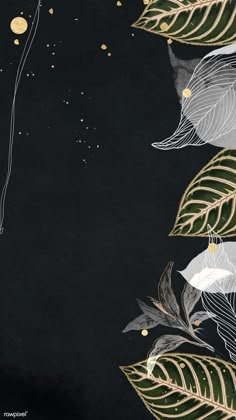

This image is a dark, elegant canvas adorned with golden and white botanical illustrations, almost like delicate whispers of nature against a starry night backdrop. It evokes a sense of quiet mystery, where leaves float like celestial beings caught between worlds.

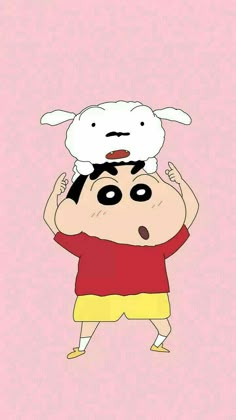

A playful moment captured as a curious child dons a fluffy white dog hat, merging innocence with goofy charm. It’s a whimsical blend of imagination and childhood fun set against a soft pink backdrop.

In [77]:
await summarise_images("https://in.pinterest.com/ashitasrivastava/drawings-to-make/")